# 4. Errors and learning curves

Class and subject analyses use LOSO predictions. MLP and XGBoost learning curves use a separate subject-disjoint fixed split.

MLP training is measured in epochs; XGBoost training is measured in boosting rounds. LR solver iterations and RF tree counts are not equivalent to neural-network epochs.


In [1]:
from pathlib import Path
import os
import sys
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
             if (p / 'har_utils.py').exists() and (p / 'comparison_utils.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Project root not found.')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
sys.path.insert(0, str(ROOT))
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from har_utils import SEED, LABELS, ACTIVITIES, feature_columns, models
from comparison_utils import (OUT, prepare_windows, validate_windows,
                              run_baseline, load_baseline, neural_diagnostic,
                              boosting_diagnostic, comparison_models as models)
OUT.mkdir(parents=True, exist_ok=True)
FIGURES = OUT / 'figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})
def finish_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()

SELECTED_MODELS = os.environ.get('HAR_MODELS', 'LR,RF,XGBoost,MLP').split(',')


In [2]:
ERROR_MODEL = 'RF'
datasets = {s: prepare_windows(s) for s in (1, 2)}
estimator = models()[ERROR_MODEL]
baseline_outputs = {}
if ERROR_MODEL in SELECTED_MODELS:
    for s, (X, meta) in datasets.items():
        validate_windows(X, meta)
        baseline_outputs[s] = load_baseline(X[feature_columns(X)], meta, estimator, ERROR_MODEL, s)
    print('Loaded complete, matching RF LOSO runs for both durations.')


Loaded complete, matching RF LOSO runs for both durations.


## Baseline confusion matrices and class scores


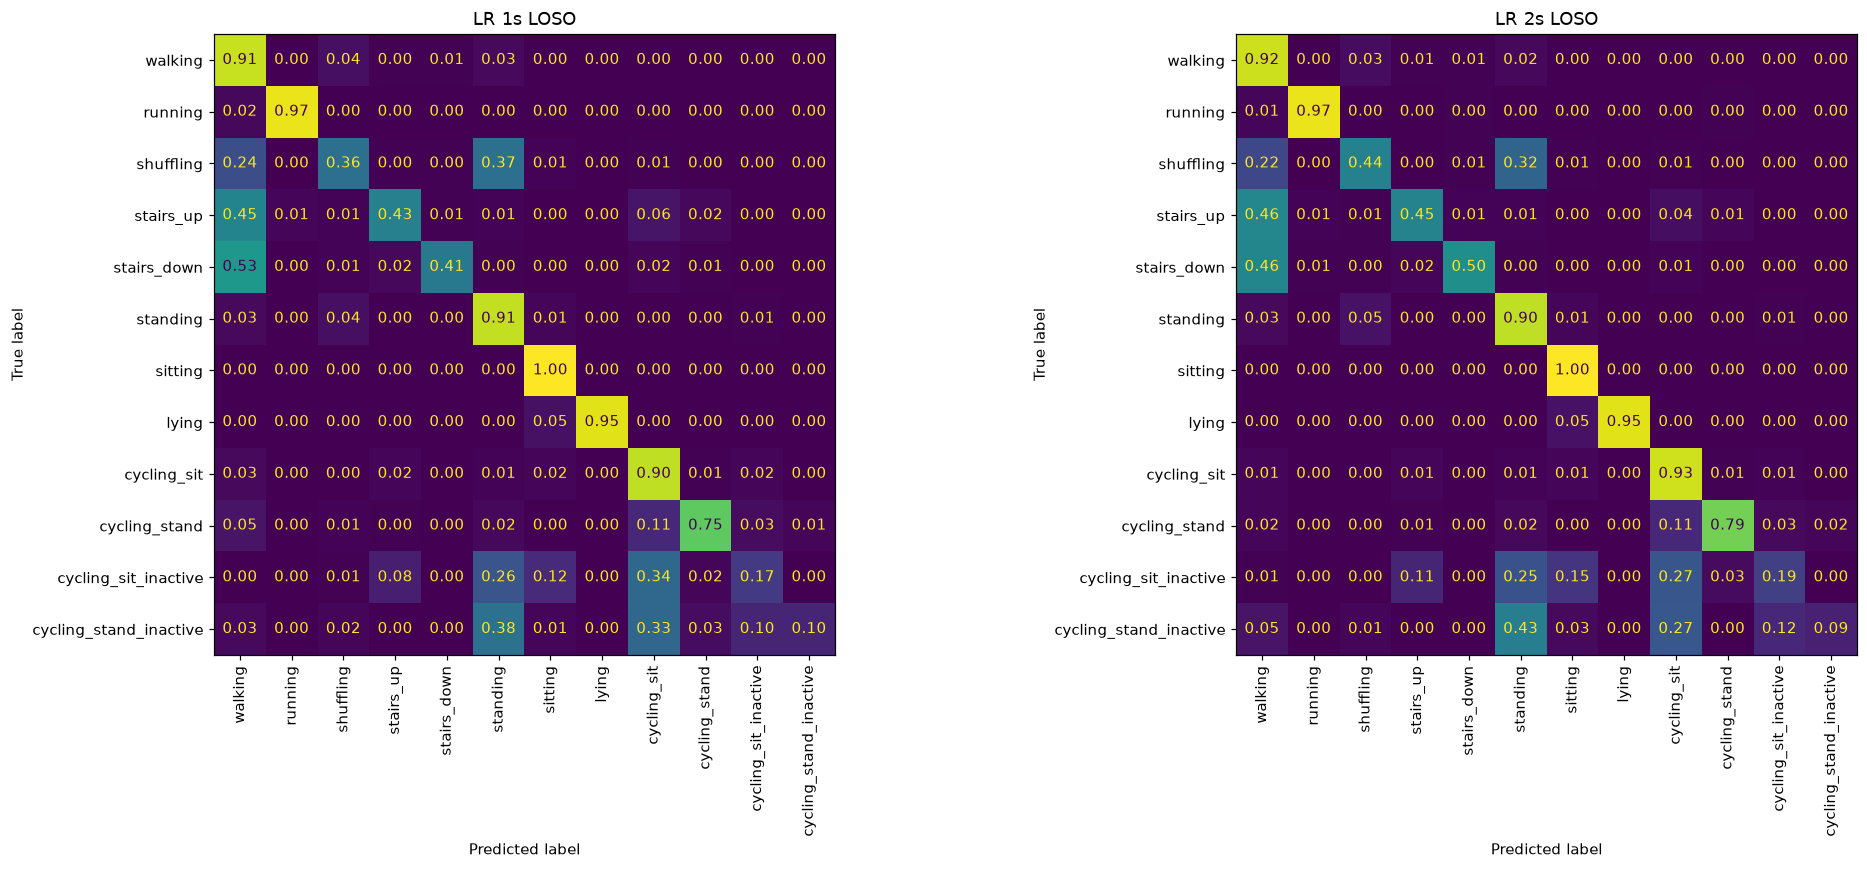

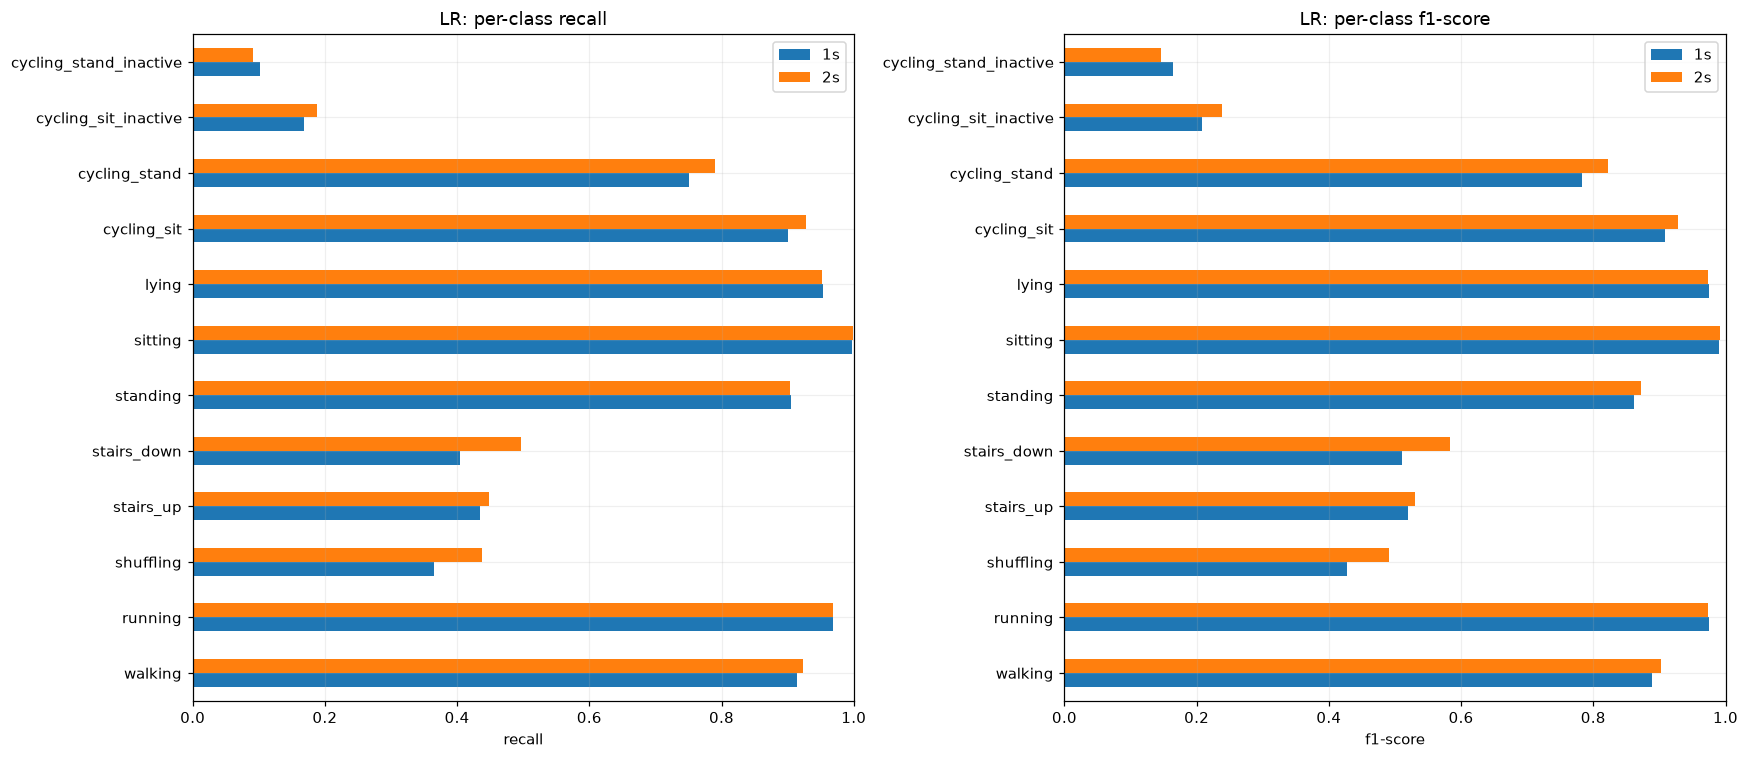

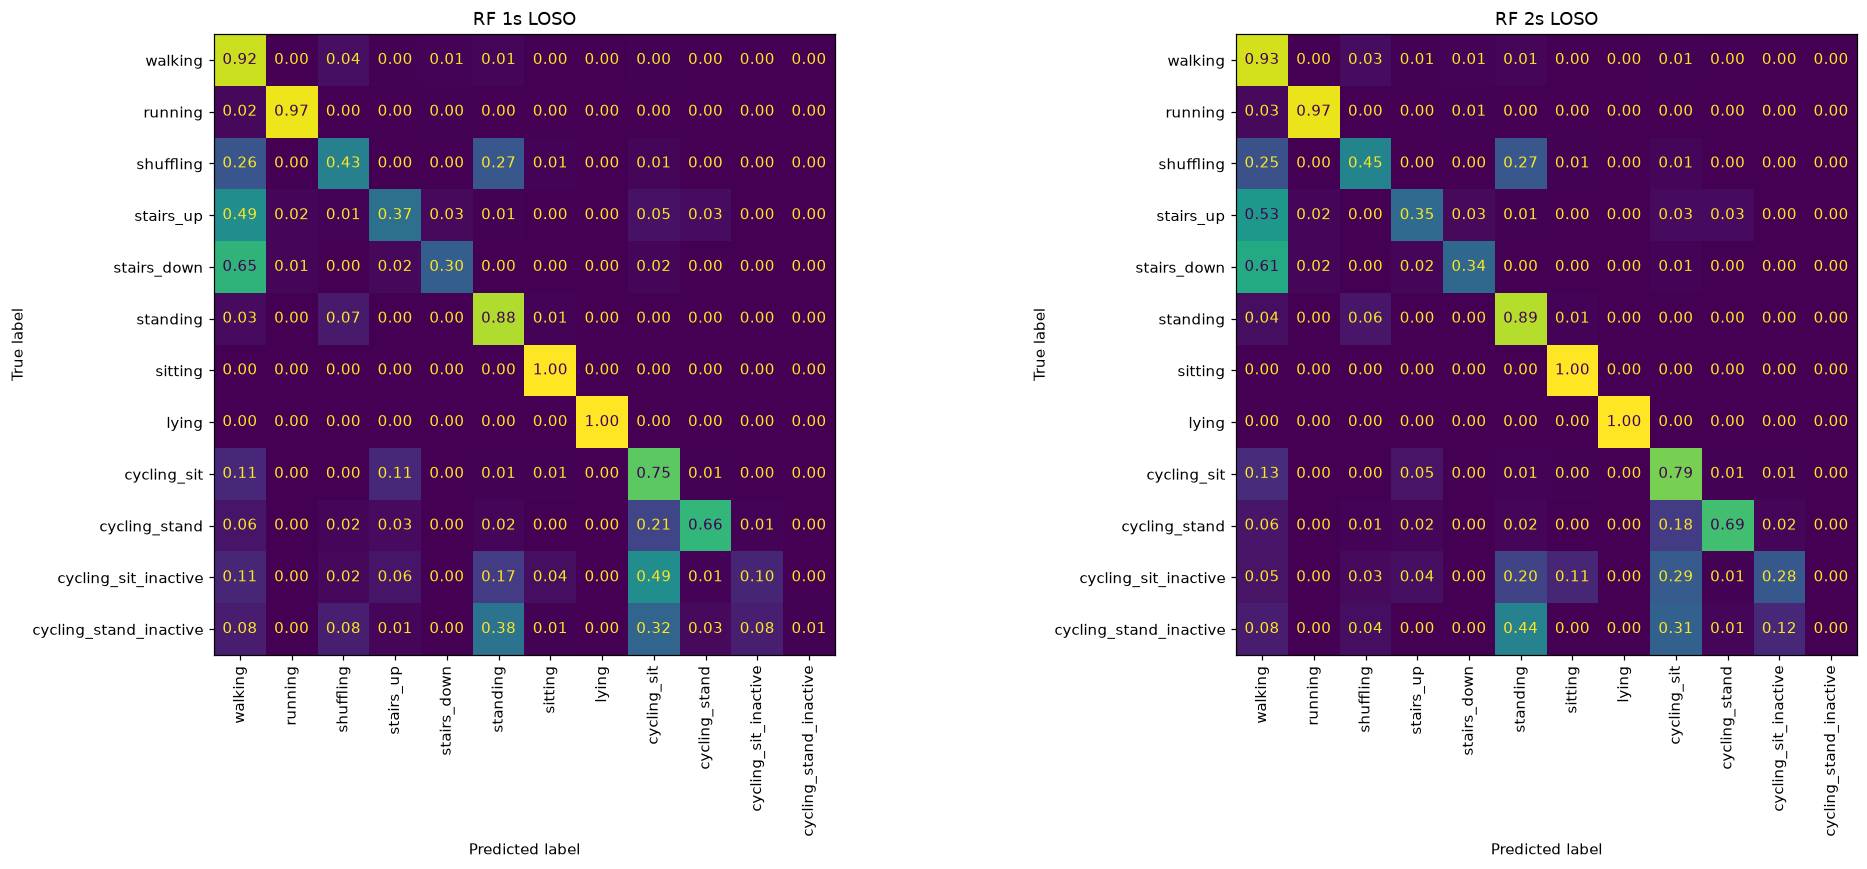

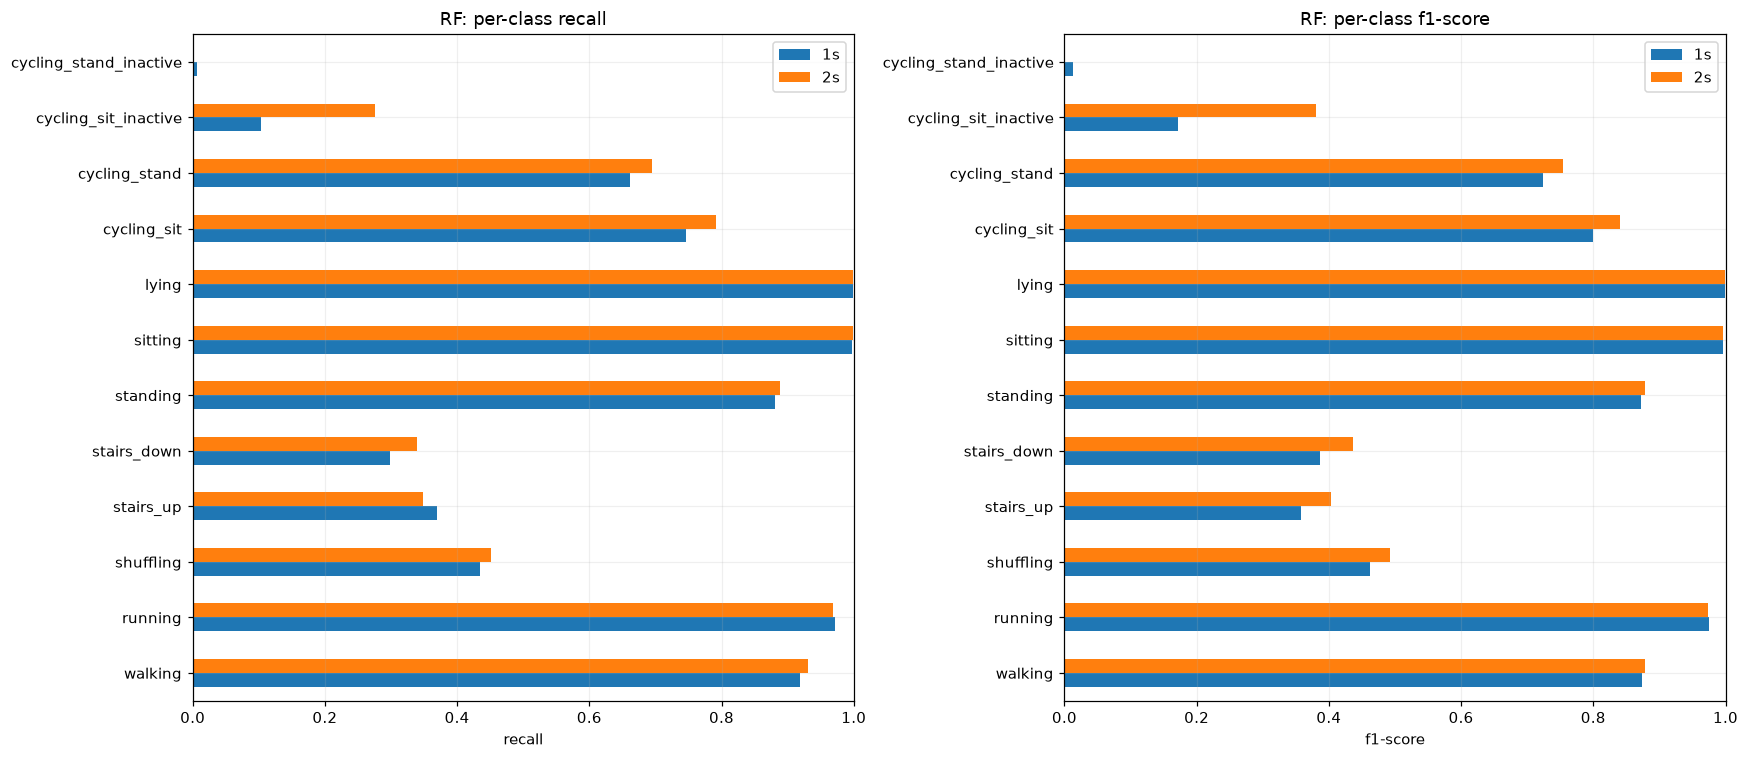

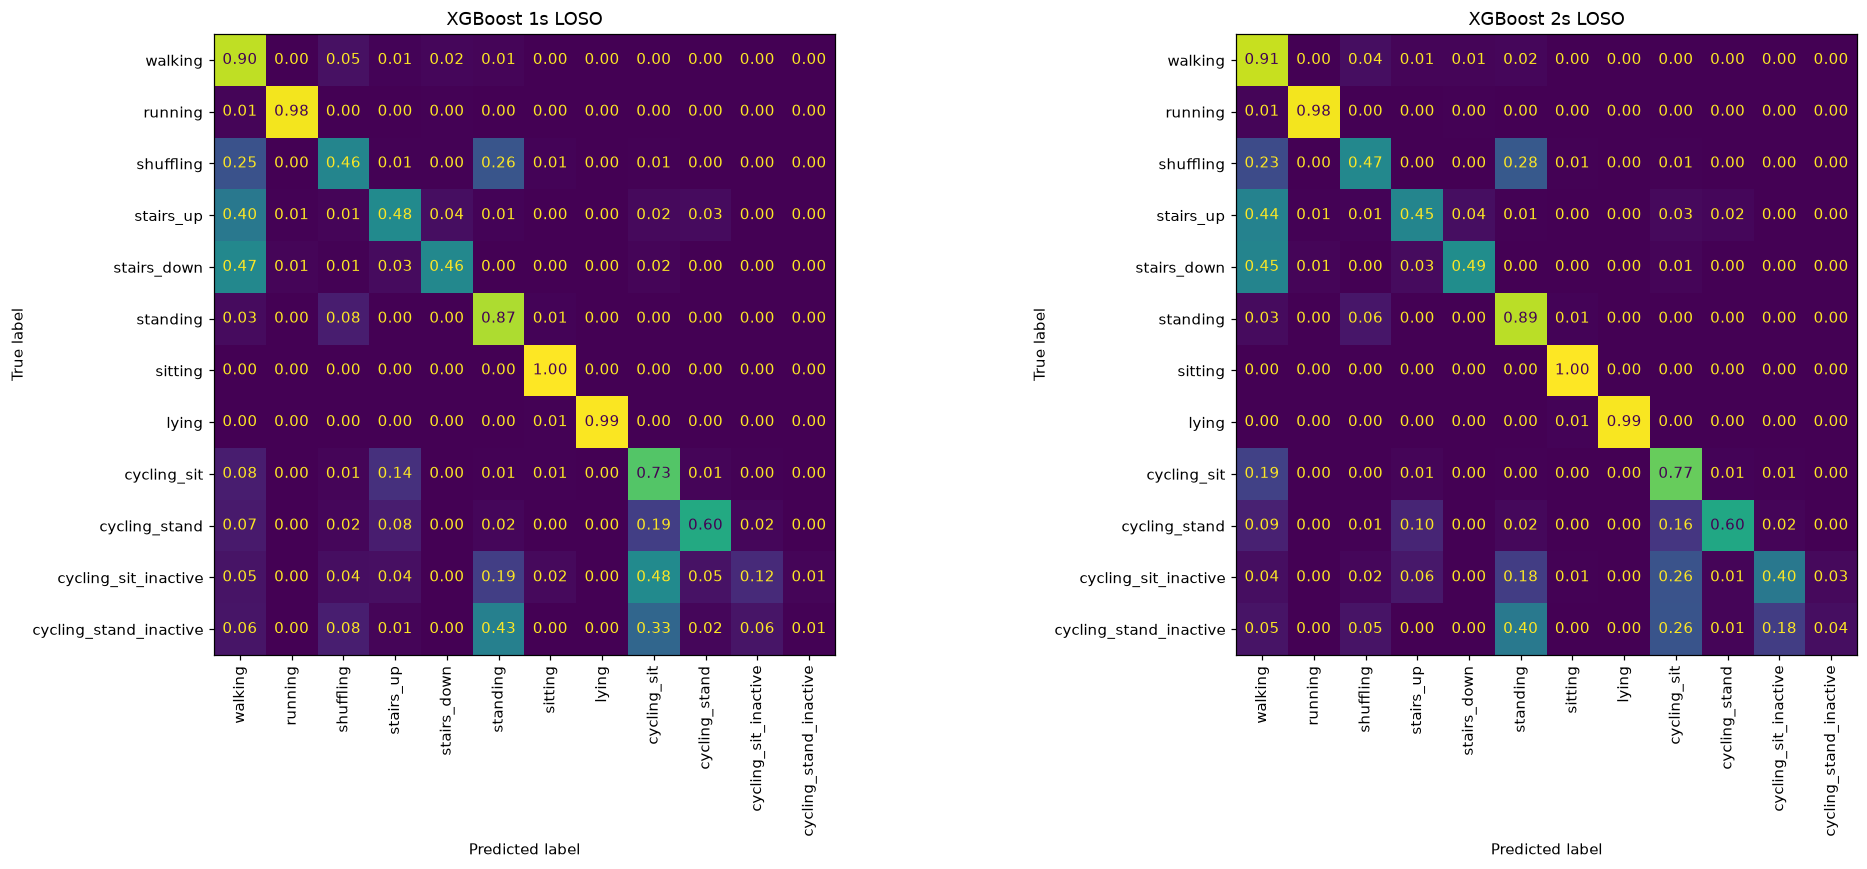

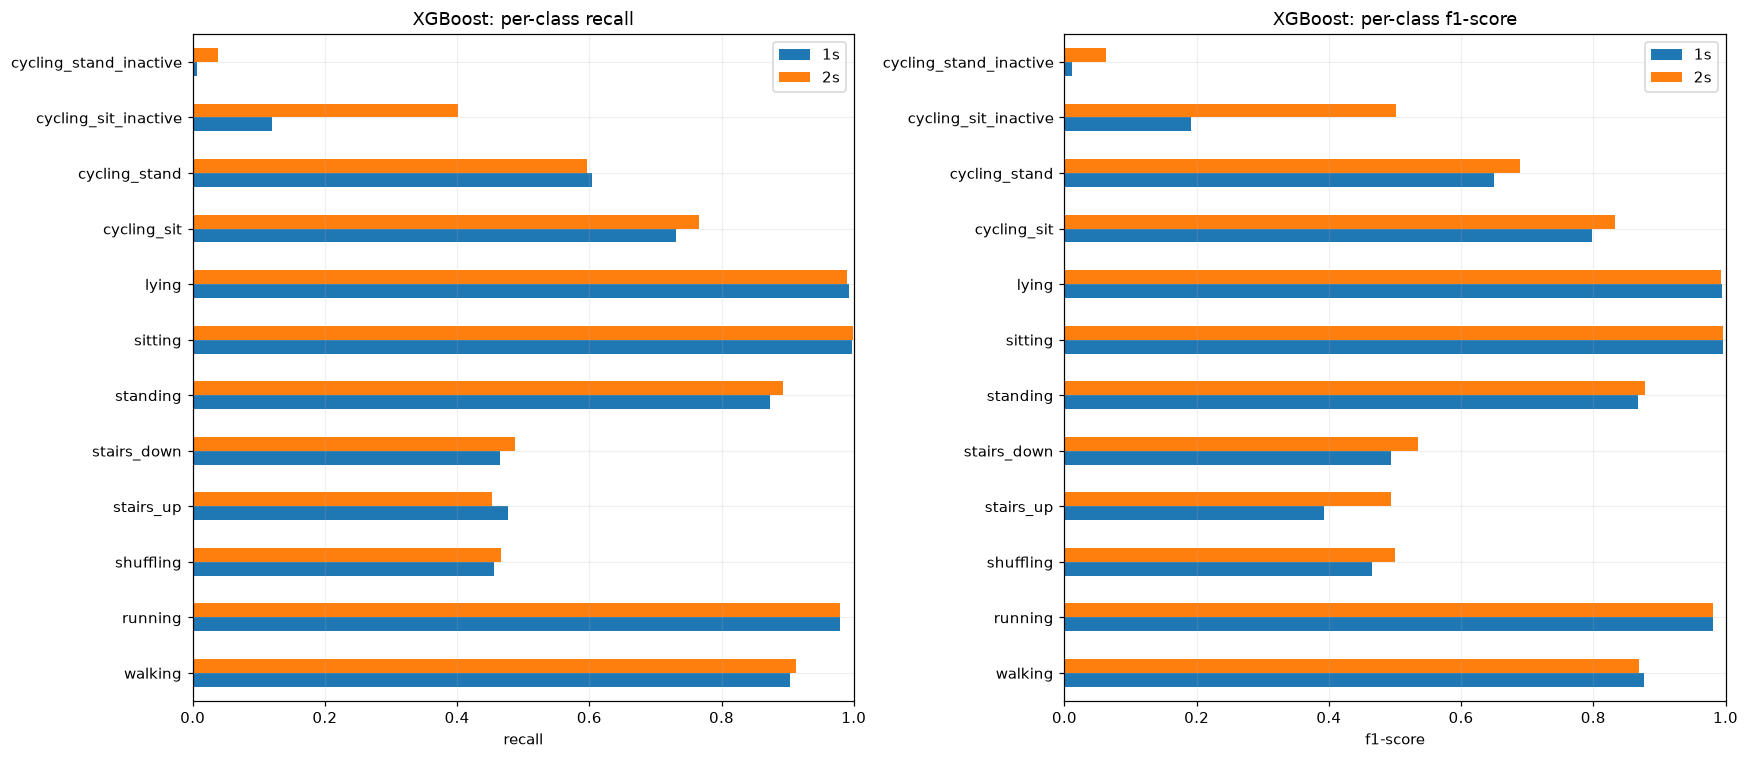

In [3]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
for name, model in models().items():
    if name not in SELECTED_MODELS:
        continue
    class_reports = {}
    fig, axes = plt.subplots(1, 2, figsize=(19, 8))
    for ax, s in zip(axes, (1, 2)):
        X, meta = datasets[s]
        _, p = load_baseline(X[feature_columns(X)], meta, model, name, s)
        report = pd.DataFrame(classification_report(p.label, p.predicted,
            labels=LABELS, target_names=list(ACTIVITIES.values()),
            output_dict=True, zero_division=0)).T
        report.to_csv(OUT / f'{name}_{s}s_all_class_report.csv')
        class_reports[s] = report
        ConfusionMatrixDisplay.from_predictions(p.label, p.predicted,
            labels=LABELS, display_labels=list(ACTIVITIES.values()), normalize='true',
            xticks_rotation=90, ax=ax, colorbar=False, values_format='.2f')
        ax.set_title(f'{name} {s}s LOSO'); ax.grid(False)
    finish_figure(f'{name}_all_confusion_matrices')
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    for metric, ax in zip(['recall', 'f1-score'], axes):
        pd.DataFrame({f'{s}s': r.loc[list(ACTIVITIES.values()), metric]
                      for s, r in class_reports.items()}).plot.barh(ax=ax)
        ax.set(title=f'{name}: per-class {metric}', xlabel=metric, xlim=(0, 1))
    finish_figure(f'{name}_all_class_scores')


## Pooled class reports

Reports pool windows; LOSO summaries weight subjects equally. Confusion matrices are row-normalized.


1s pooled-window report


,precision,recall,f1-score,support
walking,0.831,0.919,0.873,23405.000
running,0.979,0.971,0.975,5822.000
shuffling,0.494,0.435,0.462,4729.000
stairs_up,0.347,0.369,0.358,1495.000
stairs_down,0.550,0.298,0.386,1316.000
standing,0.865,0.881,0.873,13591.000
sitting,0.995,0.998,0.996,52939.000
lying,0.999,0.998,0.998,8275.000
cycling_sit,0.861,0.747,0.800,7372.000
cycling_stand,0.798,0.662,0.724,1054.000


2s pooled-window report


,precision,recall,f1-score,support
walking,0.831,0.931,0.878,11731.000
running,0.978,0.968,0.973,2910.000
shuffling,0.541,0.451,0.492,2201.000
stairs_up,0.481,0.348,0.404,779.000
stairs_down,0.614,0.339,0.437,681.000
standing,0.867,0.888,0.878,6773.000
sitting,0.995,0.999,0.997,26437.000
lying,1.000,0.999,0.999,4113.000
cycling_sit,0.896,0.792,0.841,3690.000
cycling_stand,0.826,0.695,0.755,518.000


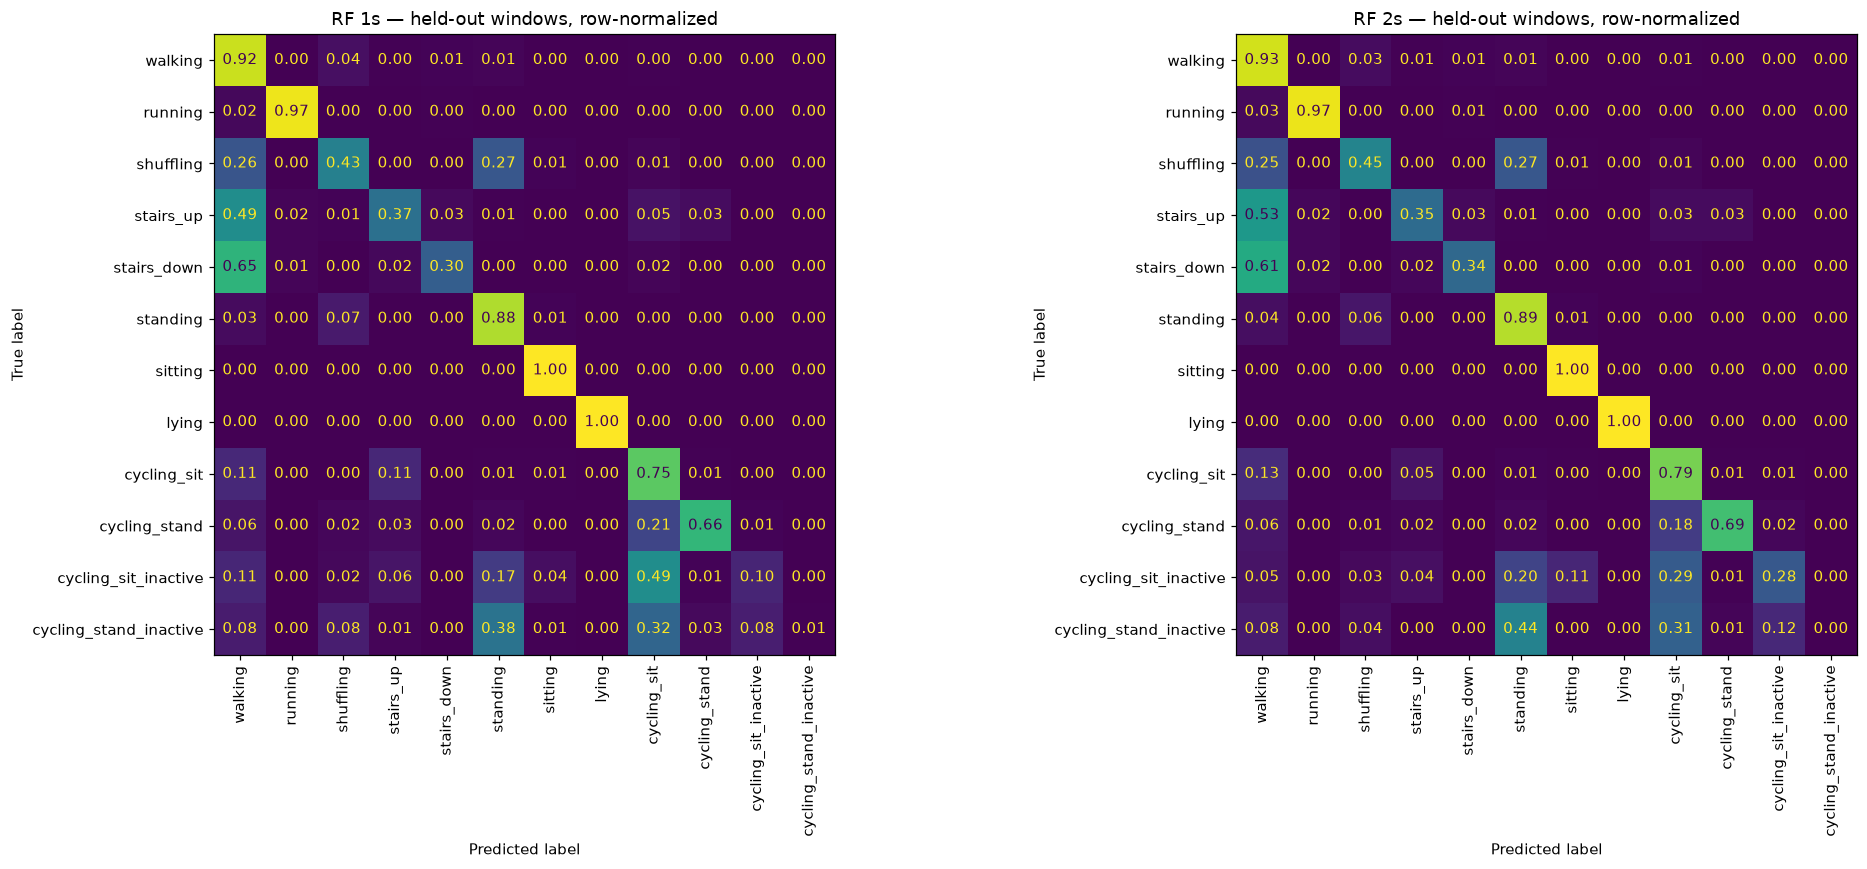

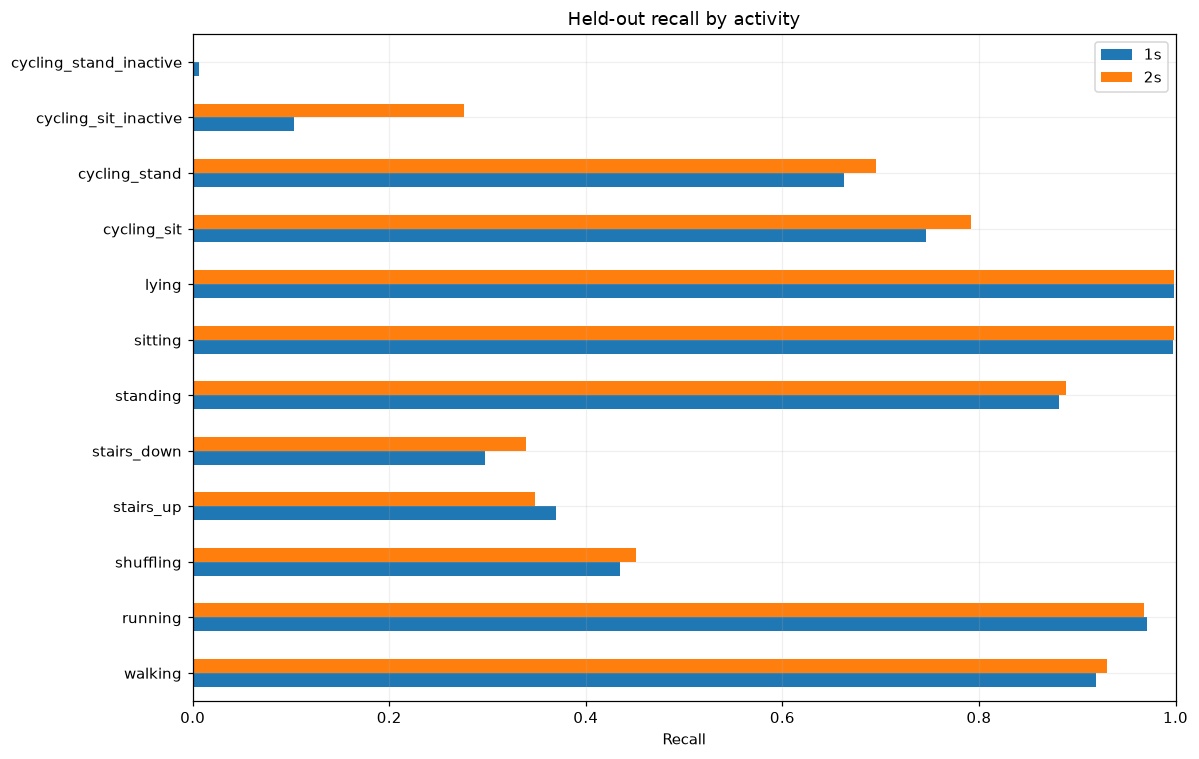

In [4]:
if baseline_outputs:
    from sklearn.metrics import classification_report, ConfusionMatrixDisplay
    reports = {}
    for s, (_, pred) in baseline_outputs.items():
        report = pd.DataFrame(classification_report(pred.label, pred.predicted,
            labels=LABELS, target_names=list(ACTIVITIES.values()),
            output_dict=True, zero_division=0)).T
        report.to_csv(OUT / f'{ERROR_MODEL}_{s}s_classification_report.csv')
        reports[s] = report
        print(f'{s}s pooled-window report')
        display(report.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(19, 8))
    for ax, (s, (_, pred)) in zip(axes, baseline_outputs.items()):
        ConfusionMatrixDisplay.from_predictions(pred.label, pred.predicted,
            labels=LABELS, display_labels=list(ACTIVITIES.values()), normalize='true',
            xticks_rotation=90, ax=ax, colorbar=False, values_format='.2f')
        ax.set_title(f'{ERROR_MODEL} {s}s — held-out windows, row-normalized')
        ax.grid(False)
    finish_figure('rf_confusion_matrices')
    per_class = pd.DataFrame({f'{s}s': report.loc[list(ACTIVITIES.values()), 'recall']
                              for s, report in reports.items()})
    per_class.to_csv(OUT / 'rf_per_class_recall.csv')
    per_class.plot.barh(figsize=(11, 7))
    plt.xlabel('Recall'); plt.xlim(0, 1); plt.title('Held-out recall by activity')
    finish_figure('rf_per_class_recall')


## Subject and transition errors

Pure/mixed-window accuracy is descriptive; label purity is not a predictor.


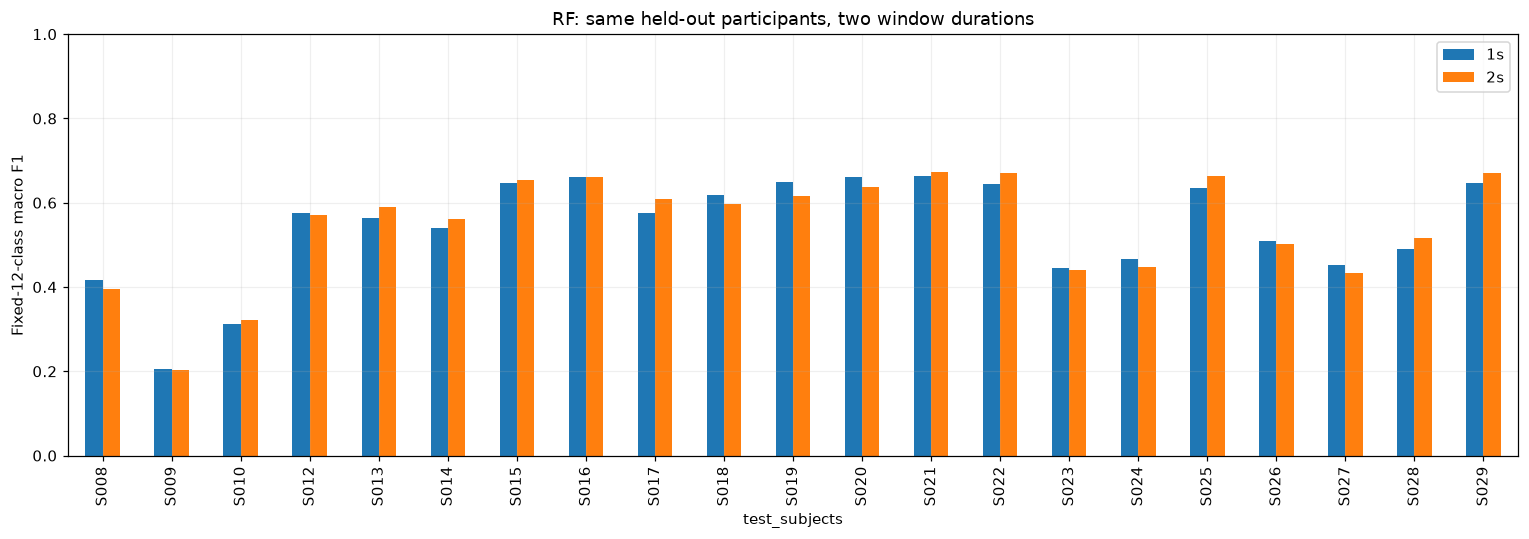

1s most common errors


wrong_windows
true                 predicted                 
shuffling            standing              1287
                     walking               1250
standing             shuffling             1001
walking              shuffling              999
stairs_down          walking                853
cycling_sit          walking                840
                     stairs_up              814
stairs_up            walking                731
standing             walking                390
walking              standing               332
cycling_sit_inactive cycling_sit            299
cycling_stand        cycling_sit            218

2s most common errors


wrong_windows
true          predicted                 
shuffling     standing               601
              walking                547
cycling_sit   walking                463
stairs_down   walking                417
stairs_up     walking                416
standing      shuffling              416
walking       shuffling              385
standing      walking                242
cycling_sit   stairs_up              197
walking       standing               161
              stairs_down             94
cycling_stand cycling_sit             92

,window_type,windows,accuracy,window_seconds
0,mixed,5467,0.482897,1
1,pure,115298,0.926902,1
2,mixed,4854,0.548620,2
3,pure,55360,0.947525,2


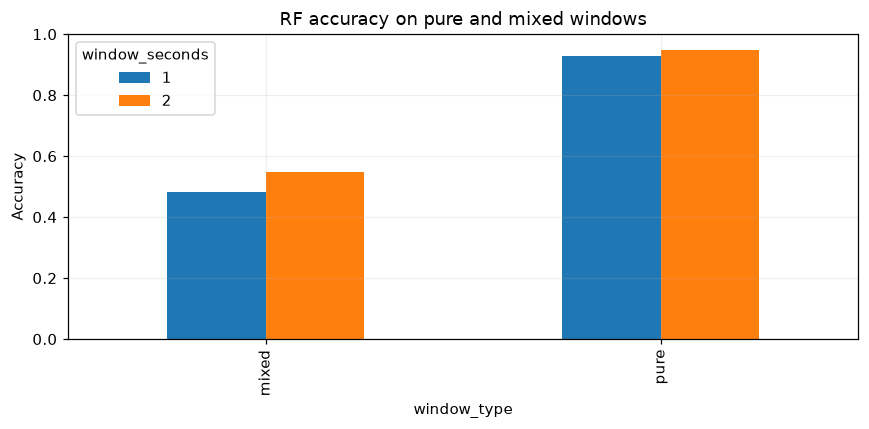

In [5]:
if baseline_outputs:
    subject_scores = pd.DataFrame({f'{s}s': folds.set_index('test_subjects').macro_f1
                                   for s, (folds, _) in baseline_outputs.items()})
    subject_scores = subject_scores.sort_index()
    subject_scores.to_csv(OUT / 'rf_subject_macro_f1.csv')
    subject_scores.plot.bar(figsize=(14, 5))
    plt.ylabel('Fixed-12-class macro F1'); plt.ylim(0, 1)
    plt.title('RF: same held-out participants, two window durations')
    finish_figure('rf_subject_scores')
    purity_tables = []
    for s, (_, saved) in baseline_outputs.items():
        pred = saved.assign(correct=saved.label == saved.predicted,
                            window_type=np.where(saved.purity == 1, 'pure', 'mixed'))
        table = pred.groupby('window_type').agg(windows=('correct', 'size'), accuracy=('correct', 'mean'))
        table['window_seconds'] = s
        purity_tables.append(table.reset_index())
        errors = pred[pred.label != pred.predicted]
        confusions = errors.groupby(['label', 'predicted']).size().sort_values(ascending=False).head(12)
        confusions.index = pd.MultiIndex.from_tuples(
            [(ACTIVITIES[a], ACTIVITIES[b]) for a, b in confusions.index], names=['true', 'predicted'])
        confusions.to_csv(OUT / f'rf_{s}s_top_confusions.csv', header=['wrong_windows'])
        print(f'{s}s most common errors')
        display(confusions.to_frame('wrong_windows'))
        errors.to_csv(OUT / f'rf_{s}s_error_windows.csv', index=False)
    purity_summary = pd.concat(purity_tables, ignore_index=True)
    purity_summary.to_csv(OUT / 'rf_pure_mixed_accuracy.csv', index=False)
    display(purity_summary)
    purity_summary.pivot(index='window_type', columns='window_seconds', values='accuracy').plot.bar(figsize=(8, 4))
    plt.ylabel('Accuracy'); plt.ylim(0, 1); plt.title('RF accuracy on pure and mixed windows')
    finish_figure('rf_pure_mixed_accuracy')


## MLP learning curves

Hidden layers: 64/32; Adam; 30 epochs; batch size 256. Sorted subject IDs assign 13 train, 4 validation and 4 test subjects. Scaling uses training data; minimum validation loss selects the epoch. Equal epoch budgets yield different update counts across durations.


In [6]:
if 'MLP' in SELECTED_MODELS:
    EPOCHS = 30
    BATCH_SIZE = 256
    FORCE_MLP = False
    diagnostic, subject_split = neural_diagnostic(
        datasets, epochs=EPOCHS, batch_size=BATCH_SIZE, force=FORCE_MLP)
    display(pd.Series(subject_split, name='subjects'))
    history = pd.concat([value[0] for value in diagnostic.values()], ignore_index=True)
    history.to_csv(OUT / 'mlp_epoch_history.csv', index=False)
    test_metrics = pd.DataFrame([value[1] for value in diagnostic.values()])
    test_metrics.to_csv(OUT / 'mlp_diagnostic_test_metrics.csv', index=False)
    display(test_metrics.round(4))


MLP 1s epoch 1/30: train=0.2816, val=0.2997


MLP 1s epoch 2/30: train=0.2346, val=0.2759


MLP 1s epoch 3/30: train=0.2147, val=0.2778


MLP 1s epoch 4/30: train=0.2037, val=0.2777


MLP 1s epoch 5/30: train=0.1956, val=0.2786


MLP 1s epoch 6/30: train=0.1880, val=0.2779


... (52 outputs left out)

MLP 2s epoch 29/30: train=0.1305, val=0.2605


MLP 2s epoch 30/30: train=0.1309, val=0.2742


test                                   [S008, S009, S010, S012]
validation                             [S013, S014, S015, S016]
train         [S017, S018, S019, S020, S021, S022, S023, S02...
Name: subjects, dtype: object

,window_seconds,best_epoch,validation_loss,fit_seconds,accuracy,macro_f1,present_class_macro_f1
0,1,13,0.2665,15.1543,0.8928,0.6065,0.6065
1,2,16,0.2472,6.9941,0.8702,0.5965,0.5965


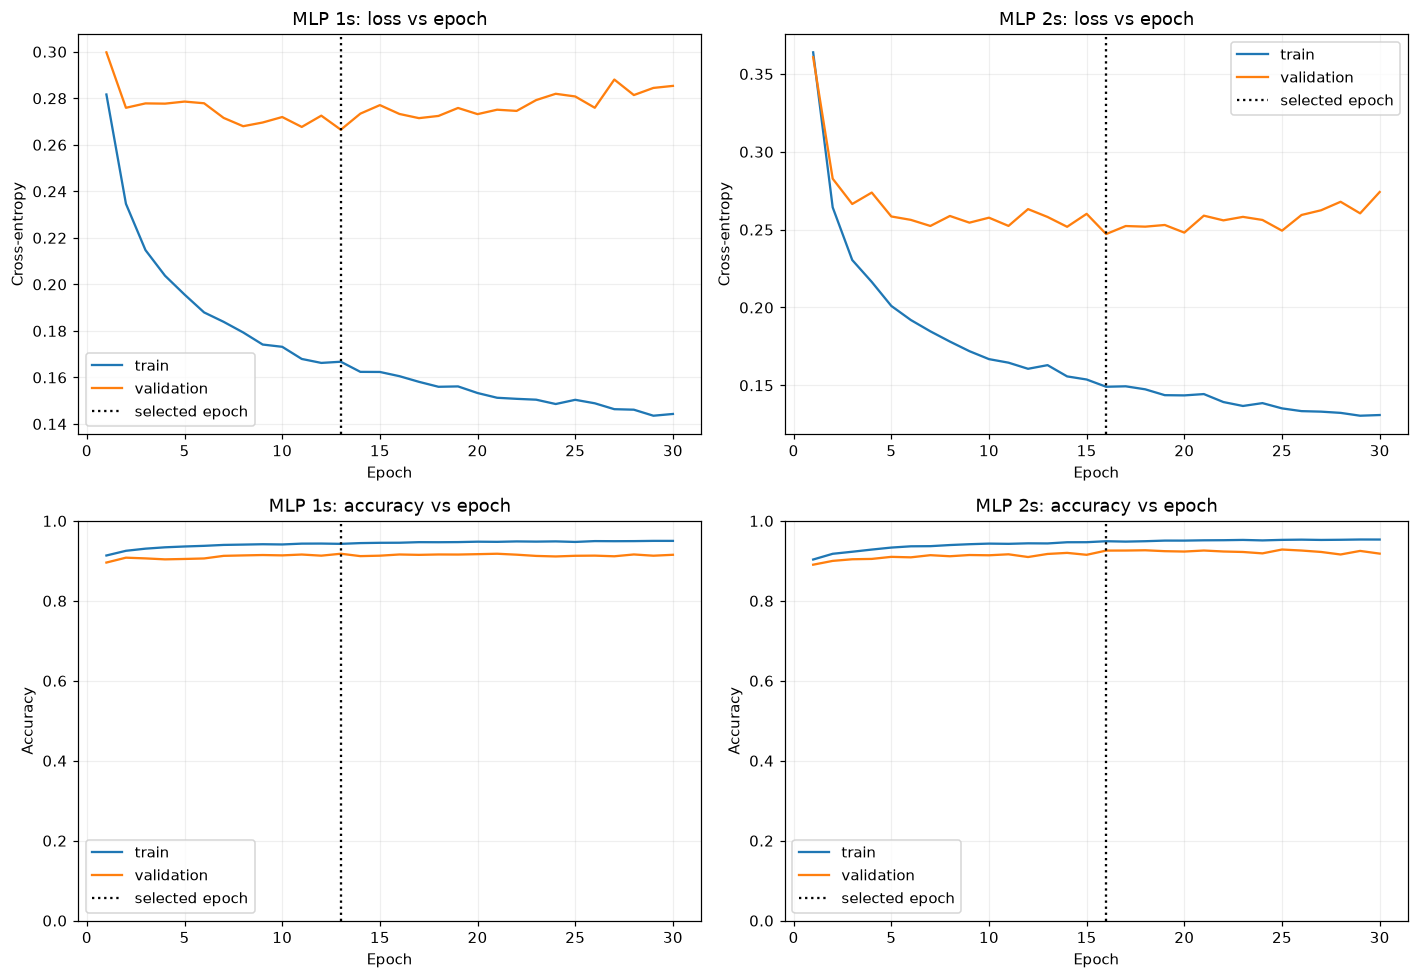

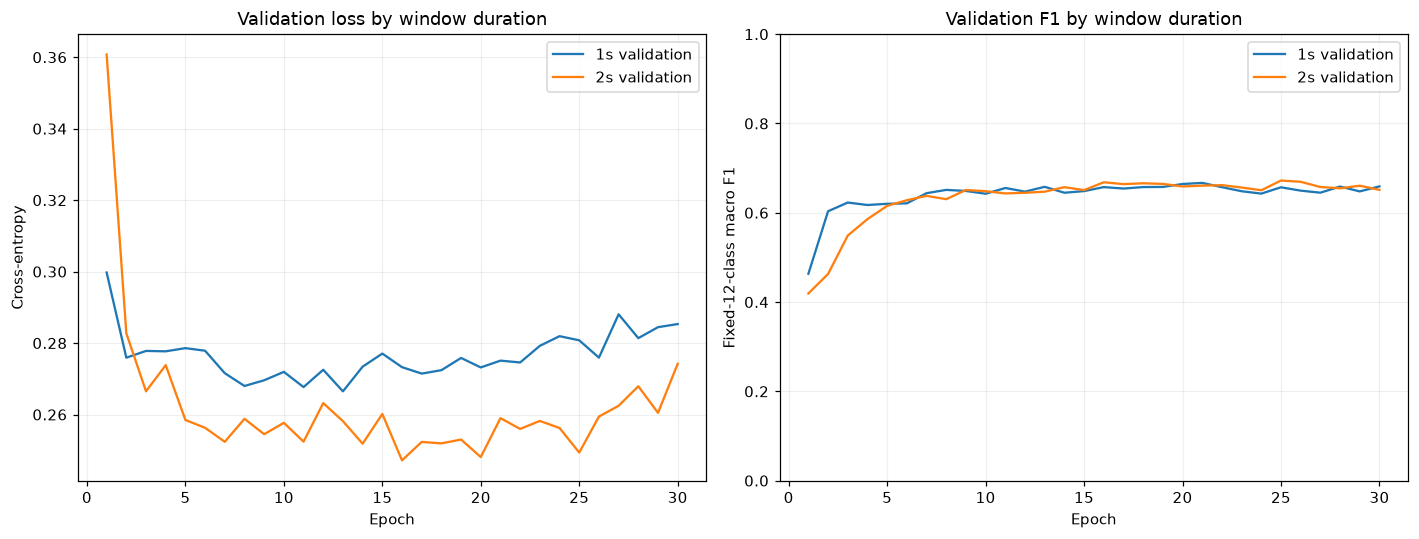

In [7]:
if 'MLP' in SELECTED_MODELS:
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for col, s in enumerate((1, 2)):
        h, result, _ = diagnostic[s]
        for role in ['train', 'validation']:
            axes[0, col].plot(h.epoch, h[f'{role}_loss'], label=role)
            axes[1, col].plot(h.epoch, h[f'{role}_accuracy'], label=role)
        for ax in axes[:, col]:
            ax.axvline(result['best_epoch'], linestyle=':', color='black', label='selected epoch')
            ax.set_xlabel('Epoch'); ax.legend()
        axes[0, col].set(title=f'MLP {s}s: loss vs epoch', ylabel='Cross-entropy')
        axes[1, col].set(title=f'MLP {s}s: accuracy vs epoch', ylabel='Accuracy', ylim=(0, 1))
    finish_figure('mlp_loss_and_accuracy_vs_epoch')
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for s, (h, _, _) in diagnostic.items():
        axes[0].plot(h.epoch, h.validation_loss, label=f'{s}s validation')
        axes[1].plot(h.epoch, h.validation_macro_f1, label=f'{s}s validation')
    axes[0].set(xlabel='Epoch', ylabel='Cross-entropy', title='Validation loss by window duration')
    axes[1].set(xlabel='Epoch', ylabel='Fixed-12-class macro F1', title='Validation F1 by window duration', ylim=(0, 1))
    for ax in axes: ax.legend()
    finish_figure('mlp_validation_duration_comparison')


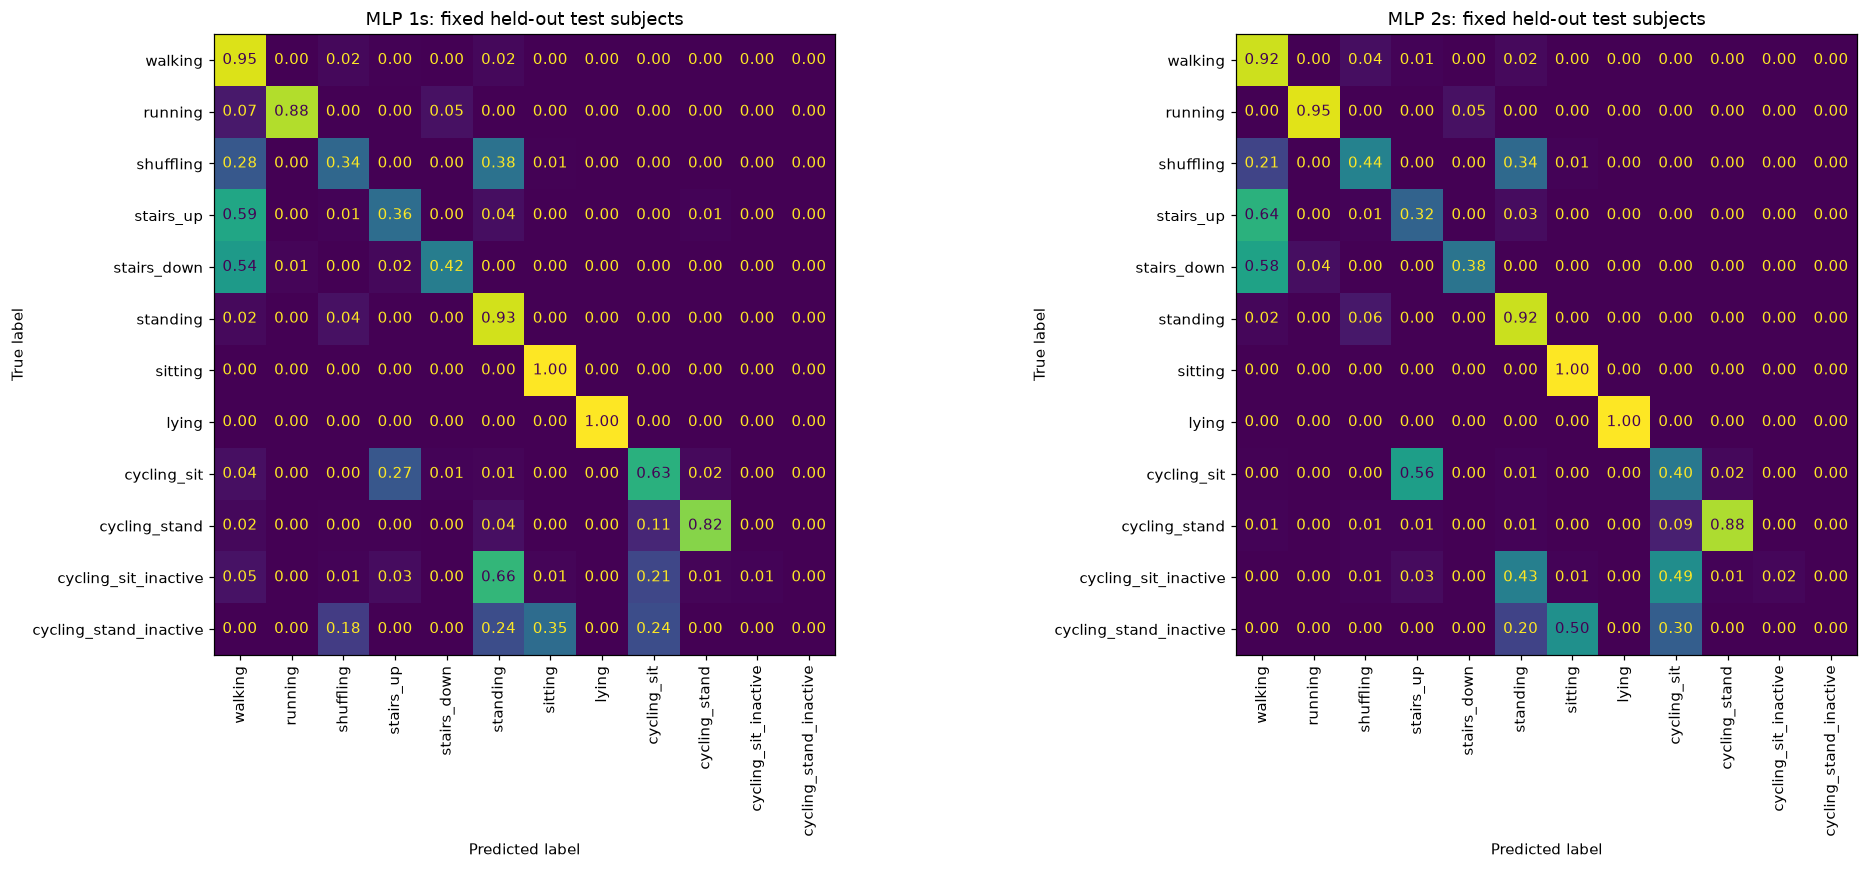

In [8]:
if 'MLP' in SELECTED_MODELS:
    fig, axes = plt.subplots(1, 2, figsize=(19, 8))
    for ax, (s, (_, _, pred)) in zip(axes, diagnostic.items()):
        ConfusionMatrixDisplay.from_predictions(pred.label, pred.predicted,
            labels=LABELS, display_labels=list(ACTIVITIES.values()), normalize='true',
            xticks_rotation=90, ax=ax, colorbar=False, values_format='.2f')
        ax.set_title(f'MLP {s}s: fixed held-out test subjects'); ax.grid(False)
        report = pd.DataFrame(classification_report(pred.label, pred.predicted,
            labels=LABELS, target_names=list(ACTIVITIES.values()),
            output_dict=True, zero_division=0)).T
        report.to_csv(OUT / f'mlp_{s}s_diagnostic_classification_report.csv')
    finish_figure('mlp_diagnostic_test_confusions')


## XGBoost learning curves

The same fixed split is used. Minimum validation loss selects the boosting round before test evaluation.


[0]	train-mlogloss:1.50448	validation-mlogloss:1.41751


[25]	train-mlogloss:0.27486	validation-mlogloss:0.34804


[50]	train-mlogloss:0.16794	validation-mlogloss:0.26470


[75]	train-mlogloss:0.13828	validation-mlogloss:0.25210


[100]	train-mlogloss:0.12134	validation-mlogloss:0.25236


[125]	train-mlogloss:0.10950	validation-mlogloss:0.25246


... (4 outputs left out)

[75]	train-mlogloss:0.10354	validation-mlogloss:0.23311


[100]	train-mlogloss:0.08511	validation-mlogloss:0.22977


[125]	train-mlogloss:0.07227	validation-mlogloss:0.22691


[149]	train-mlogloss:0.06327	validation-mlogloss:0.22757


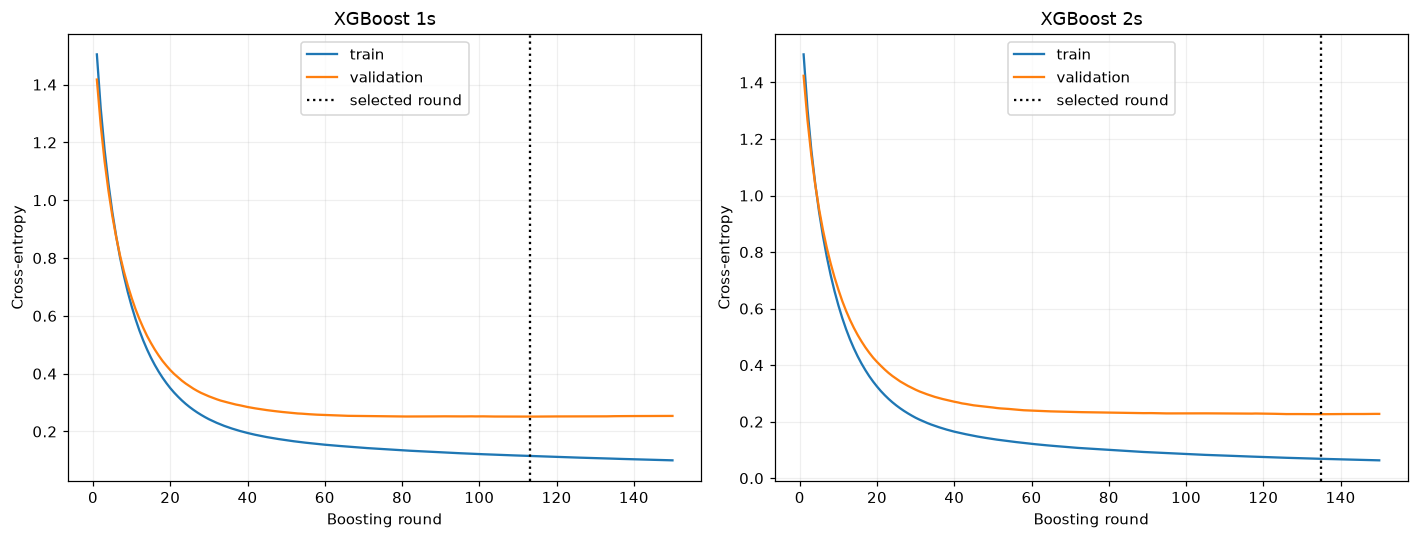

In [9]:
if 'XGBoost' in SELECTED_MODELS:
    boosting, _ = boosting_diagnostic(datasets)
    pd.concat([v[0] for v in boosting.values()], ignore_index=True).to_csv(
        OUT / 'xgboost_round_history.csv', index=False)
    pd.DataFrame([v[1] for v in boosting.values()]).to_csv(
        OUT / 'xgboost_diagnostic_test_metrics.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (s, (h, result, _)) in zip(axes, boosting.items()):
        ax.plot(h['round'], h.train_loss, label='train')
        ax.plot(h['round'], h.validation_loss, label='validation')
        ax.axvline(result['best_round'], linestyle=':', color='black', label='selected round')
        ax.set(title=f'XGBoost {s}s', xlabel='Boosting round', ylabel='Cross-entropy')
        ax.legend()
    finish_figure('xgboost_loss_vs_boosting_round')


## Evaluation limits

Fixed-split scores and LOSO means use different protocols. Model/window selection on these results is exploratory, without an independent final test.
